# Image 분류 — 실습용 완성 코드

**Colab: 런타임 → T4 GPU**. **★ 설정**만 데이터에 맞게 바꾸면 됩니다.
train 은 폴더(하위폴더=카테고리)로, test 는 별도 폴더가 주어지면 그 경로로 예측합니다.

> 변수명은 **이 파일 단독 실행** 기준(plain)입니다. 실습은 **한 커널**에서 3문제를 이어 풀어 `X`·`best`·`sub` 같은 변수가 서로 덮어써집니다 — 정형=`p1_`, 텍스트=`p2_`, 이미지=`p3_` 접두사로 문제별로 분리하세요.

## 1. 설정 · 예제 데이터 내려받기

In [6]:
import tensorflow as tf, pathlib, os, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report
SEED = 42; tf.random.set_seed(SEED)

RESULT_3 = '01012345678_3'             # 휴대폰번호_문제번호 (하이픈·공백 없이). Image=3
PRED_COL = 'pred'                      # 결과 컬럼명 (지문이 지정하면 그 이름)
IMAGE_SIZE, BATCH = (224, 224), 32
EPOCHS_1, EPOCHS_2 = 8, 5              # Phase1(동결) · Phase2(미세조정)

# ▼ (연습용) 예제 데이터 내려받기 — 실습에선 데이터가 이미 주어지므로 이 셀은 건너뜀
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'  # 꽃 5클래스
# DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/rps.zip'  # 가위바위보 3클래스
try:
    tf.keras.utils.get_file(origin=DATA_URL, extract=True, cache_dir='.', cache_subdir='data')  # 현재 폴더 ./data 에 해제
except Exception as e:
    print('다운로드/해제 건너뜀:', type(e).__name__)

# ▼ 어디에 풀렸는지 눈으로 확인 → 이미지가 들어 있는 폴더들의 '바로 위'가 data_dir
_ds = pathlib.Path('data')
print("'./data' 안 이미지 폴더 (= 카테고리):")
for _p in sorted(d for d in _ds.rglob('*') if d.is_dir()):
    _n = sum(len(glob.glob(str(_p / e))) for e in ('*.jpg', '*.jpeg', '*.png'))
    if _n:
        print(f'   {_p}   · 이미지 {_n}장')

'./data' 안 이미지 폴더 (= 카테고리):
   data/flower_photos.tgz/flower_photos/daisy   · 이미지 633장
   data/flower_photos.tgz/flower_photos/dandelion   · 이미지 898장
   data/flower_photos.tgz/flower_photos/roses   · 이미지 641장
   data/flower_photos.tgz/flower_photos/sunflowers   · 이미지 699장
   data/flower_photos.tgz/flower_photos/tulips   · 이미지 799장


In [5]:
!ls -al data/flower_photos.tgz/flower_photos/

total 624
drwxr-xr-x 7 root root   4096 Feb 10  2016 .
drwxr-xr-x 3 root root   4096 Sep  8 00:00 ..
drwxr-xr-x 2 root root  36864 Feb 10  2016 daisy
drwxr-xr-x 2 root root  53248 Feb 10  2016 dandelion
-rw-r----- 1 root root 418049 Feb  9  2016 LICENSE.txt
drwxr-xr-x 2 root root  36864 Feb 10  2016 roses
drwxr-xr-x 2 root root  36864 Feb 10  2016 sunflowers
drwxr-xr-x 2 root root  40960 Feb 10  2016 tulips


## 1b. train / test 경로 지정  ← ★ 위 목록을 보고 직접

위 셀 출력에서 **이미지 장수가 찍힌 폴더들**(=카테고리)의 **바로 위 폴더**를 `data_dir` 에 넣습니다.
실습에선 주어진 train 폴더 경로로, test 폴더가 따로 있으면 `TEST_DIR` 로 지정하세요.

In [7]:
# ★ 위 목록에서 이미지 폴더들의 '바로 위' 폴더를 직접 지정
data_dir = pathlib.Path('data') / 'flower_photos.tgz' / 'flower_photos'   # rps 면 'data/rps' / 실습: 주어진 train 폴더
# data_dir = pathlib.Path('/content/train')          # 예) train 폴더가 여기 있으면

TEST_DIR = None                        # 예: './test' (라벨 없는 test 이미지 폴더). 없으면 train 의 val 로 데모

assert data_dir.exists(), f'{data_dir} 없음 — 위 목록을 보고 실제 경로로 고치세요'
print('train 경로:', data_dir, '| 하위:', [d.name for d in data_dir.iterdir() if d.is_dir()])

train 경로: data/flower_photos.tgz/flower_photos | 하위: ['roses', 'dandelion', 'tulips', 'daisy', 'sunflowers']


## 2. 데이터 확인  (클래스별 장수)

In [8]:
for c in sorted(d.name for d in data_dir.iterdir() if d.is_dir()):
    n = sum(len(list((data_dir / c).glob(e))) for e in ('*.jpg', '*.jpeg', '*.png'))
    print(f'  {c}: {n}장')

  daisy: 633장
  dandelion: 898장
  roses: 641장
  sunflowers: 699장
  tulips: 799장


## 3. 데이터셋 생성  (train/val 같은 seed 로 분할)

In [9]:
com = dict(label_mode='categorical', image_size=IMAGE_SIZE, batch_size=BATCH, seed=SEED)
# train/val 둘 다 shuffle=True + 같은 seed → 클래스가 고루 섞여 분할된다.
#   (val 에 shuffle=False 를 쓰면 파일이 클래스 폴더 순서라 마지막 클래스만 val 로 몰림!)
train_ds = tf.keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset='training', shuffle=True, **com)
val_ds   = tf.keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset='validation', shuffle=True, **com)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
val_files = list(val_ds.file_paths)                    # val 파일 목록(고정 순서) — 평가/제출 정렬용
train_ds = train_ds.prefetch(tf.data.AUTOTUNE); val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
print('클래스', NUM_CLASSES, class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
클래스 5 ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


## 4. 모델 · 학습  (MobileNetV2 · 2단계)

In [10]:
base = tf.keras.applications.MobileNetV2(input_shape=IMAGE_SIZE + (3,), include_top=False, weights='imagenet')
base.trainable = False
inp = tf.keras.Input(IMAGE_SIZE + (3,))
x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(inp)   # MobileNetV2 는 -1~1 입력
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
out = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)   # 이진/다중 통일
model = tf.keras.Model(inp, out)

CKPT = f'{RESULT_3}_ckpt.weights.h5'
cbs = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
       tf.keras.callbacks.ModelCheckpoint(CKPT, save_best_only=True, save_weights_only=True, monitor='val_loss')]
# ↑ 두 단계가 이 콜백을 공유 → val_loss 최저 가중치가 Phase 1·2 통틀어 CKPT 에 유지됨

# Phase 1: base 동결, 분류 헤드만 (lr 1e-3)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_1, callbacks=cbs, verbose=1)

# Phase 1 이 개선 없어 조기 종료돼도, 여기부터 그대로 이어서 파인튜닝(fit 이 따로라 patience 새로 시작).
# Phase 2: 상위 30층 해제, 낮은 lr (1e-5) — 높으면 사전학습 가중치가 망가짐
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_2, callbacks=cbs, verbose=1)

# ★ 학습이 개선 못 하거나 조기 중단돼도 CKPT 엔 두 단계 통틀어 best 가 있다 → 그걸 복원 (버전 무관)
model.load_weights(CKPT)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 54s 391ms/step - accuracy: 0.6877 - loss: 0.8663 - val_accuracy: 0.8174 - val_loss: 0.5484
Epoch 2/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.8382 - loss: 0.4504 - val_accuracy: 0.8610 - val_loss: 0.3949
Epoch 3/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 82ms/step - accuracy: 0.8696 - loss: 0.3584 - val_accuracy: 0.8692 - val_loss: 0.3783
Epoch 4/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.8879 - loss: 0.3150 - val_accuracy: 0.8828 - val_loss: 0.3550
Epoch 5/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.8995 - loss: 0.2828 - val_accuracy: 0.8747 - val_loss: 0.3587
Epoch 6/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.9111 - loss: 0.2585 - val_accuracy: 0.8828 - val_loss: 0.3349
Epoch 7/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.9210 - loss: 0.2351 - val_accuracy: 0.8842 - val_loss: 0.3537
Epoch 8/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.92

## 5. 평가 · ⭐ 눈으로 확인  (val)

Val Acc 0.9087
              precision    recall  f1-score   support

       daisy       0.89      0.96      0.92       107
   dandelion       0.95      0.94      0.94       191
       roses       0.78      0.95      0.86       119
  sunflowers       0.95      0.90      0.92       135
      tulips       0.97      0.82      0.89       182

    accuracy                           0.91       734
   macro avg       0.91      0.92      0.91       734
weighted avg       0.92      0.91      0.91       734



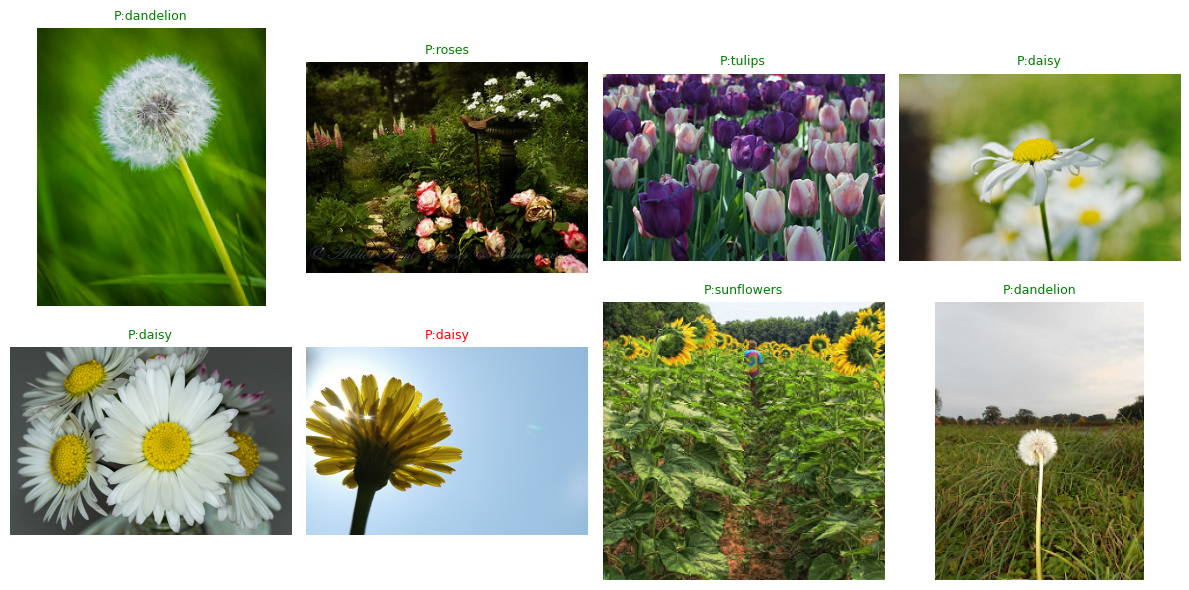

In [11]:
# 파일 경로로 직접 로드 → image_dataset 의 셔플과 무관하게 파일-예측 정렬 보장
def load_img(path):
    img = tf.image.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, IMAGE_SIZE)
def predict_files(files):
    ds = tf.data.Dataset.from_tensor_slices([str(f) for f in files]).map(load_img).batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return model.predict(ds, verbose=0).argmax(1)

val_pred = predict_files(val_files)
val_true = np.array([class_names.index(pathlib.Path(f).parent.name) for f in val_files])   # 폴더명 = 정답
print('Val Acc', round(accuracy_score(val_true, val_pred), 4))
print(classification_report(val_true, val_pred, target_names=class_names))

# ⭐ 눈으로: 초록=정답 / 빨강=오답
rng = np.random.RandomState(SEED)
plt.figure(figsize=(12, 6))
for j, i in enumerate(rng.choice(len(val_files), min(8, len(val_files)), replace=False)):
    plt.subplot(2, 4, j + 1); plt.imshow(tf.keras.utils.load_img(val_files[i])); plt.axis('off')
    ok = val_pred[i] == val_true[i]
    plt.title(f'P:{class_names[val_pred[i]]}', color='green' if ok else 'red', fontsize=9)
plt.tight_layout(); plt.show()

## 6. 결과 만들기  (test 폴더가 있으면 그걸로, 없으면 val 데모)

> 실습은 `TEST_DIR` 의 이미지들을 예측해 **filename + 결과 컬럼**으로 저장합니다. (test 는 라벨 없음)

In [12]:
if TEST_DIR:
    # 실습: 라벨 없는 test 폴더의 이미지들 (순서 고정 = 파일명 정렬)
    test_files = sorted(f for f in glob.glob(os.path.join(TEST_DIR, '**', '*.*'), recursive=True)
                        if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    assert test_files, f'{TEST_DIR} 에 이미지가 없습니다'
    sub_files = test_files
    sub_pred = predict_files(test_files)
else:
    sub_files, sub_pred = val_files, val_pred          # 데모: 위 val 예측 재사용

sub = pd.DataFrame({'filename': [os.path.basename(f) for f in sub_files],
                    PRED_COL: [class_names[i] for i in sub_pred]})
print('행수', len(sub), '| 예측 분포:', dict(pd.Series(sub[PRED_COL]).value_counts()))
sub.head(10)

행수 734 | 예측 분포: {'dandelion': np.int64(190), 'tulips': np.int64(155), 'roses': np.int64(145), 'sunflowers': np.int64(128), 'daisy': np.int64(116)}


,filename,pred
0,7270523166_b62fc9e5f1_m.jpg,dandelion
1,18996957833_0bd71fbbd4_m.jpg,dandelion
2,17029965300_8e755c2214_n.jpg,dandelion
3,8520482921_21dd204ebd_n.jpg,tulips
4,3951246342_930138610b_n.jpg,sunflowers
5,16643944275_3cd4cd966c.jpg,roses
6,16582481123_06e8e6b966_n.jpg,tulips
7,3150964108_24dbec4b23_m.jpg,tulips
8,444963906_e41492b692.jpg,roses
9,1128626197_3f52424215_n.jpg,dandelion


## 7. ⭐ csv · 모델 저장

> `filename + 결과 컬럼`(클래스명) csv + 모델(`.keras`).

In [13]:
CSV, MODEL = f'{RESULT_3}.csv', f'{RESULT_3}.keras'
assert sub[PRED_COL].isnull().sum() == 0, '예측 결측'     # ★ 저장 전에 검증
sub.to_csv(CSV, index=False)
model.save(MODEL)
print('저장 완료:', [f for f in os.listdir('.') if f.startswith(RESULT_3)])

저장 완료: ['01012345678_3_ckpt.weights.h5', '01012345678_3.keras', '01012345678_3.csv']
